# Transfer Learning with a pre-trained ResNet50

**Goal:** classify the 200 Tiny ImageNet classes with a ResNet50 that was pre-trained on ImageNet.

**Plan**
1. *Feature extraction:* freeze the pre-trained ResNet50 and train only a new classification head.
2. *Fine-tuning:* unfreeze the top layers of ResNet50 and continue training with a small learning rate (next step).

The data comes from `Preprocessing.ipynb`: corrected images (`images_corrected/`) and corrected labels (`labels_corrected.csv`).
The test split is only used at the very end.

## 1. Environment setup
Same setup as in the other notebooks: on Colab the repository (code and data) is cloned to `/content/ImageClassification`.

In [ ]:
import os, sys, subprocess
import warnings
warnings.filterwarnings('ignore')

REPO_URL = 'https://github.com/durak-dev/ImageClassification.git'
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    # Colab starts with an empty VM: clone the repo (code AND data live in it).
    # On later runs the folder already exists, so just pull the newest commits.
    ROOT = '/content/ImageClassification'
    if not os.path.exists(ROOT):
        subprocess.run(['git', 'clone', REPO_URL, ROOT], check=True)
    else:
        subprocess.run(['git', '-C', ROOT, 'pull'], check=True)
else:
    # Local: the notebook sits in the project root, but also work if it was
    # started from a subfolder.
    cwd = os.path.abspath(os.getcwd())
    ROOT = cwd if os.path.isdir(os.path.join(cwd, 'utils')) else os.path.dirname(cwd)

os.chdir(ROOT)
sys.path.insert(0, ROOT)          # so `import utils.funcs` finds OUR utils folder

DATA_DIR = os.path.join(ROOT, 'data')
ORIG_DIR = os.path.join(DATA_DIR, 'original')            # raw images/ + labels/ (placed manually, never modified)
MANIFEST_PATH = os.path.join(DATA_DIR, 'split_manifest.csv')   # which file belongs to which split
SEED = 42
print('Running on:', 'Google Colab' if IN_COLAB else 'local machine')
print('Project root:', ROOT)

## 2. Imports

In [ ]:
import importlib
import utils.funcs
importlib.reload(utils.funcs)      # pick up edits to funcs.py without restarting
from utils.funcs import *
from utils.github_sync import load_csv

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(SEED)   # reproducibility
print("TensorFlow", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

## 3. Rebuild the corrected data splits
On a fresh Colab VM `data/train`, `data/val` and `data/test` do not exist yet. They are rebuilt from the files in the repository (split manifest + checkpoints of `Preprocessing.ipynb`).

In [ ]:
# Recreate data/{split}/ with the corrected images + labels if they are missing (fresh Colab VM).
# Only needs files from the repo: split_manifest.csv, data/original/ and two checkpoints
# from Preprocessing.ipynb (df_fixed = correction strengths per image, labels_corrected).
# Set FROM_GITHUB = True if the checkpoints were saved on Colab (they live on the checkpoints branch).
FROM_GITHUB = False
if not all(os.path.exists(os.path.join(split_dir(DATA_DIR, s, 'labels'), CORRECTED_LABELS_FILE)) for s in SPLITS):
    materialize_splits(ORIG_DIR, DATA_DIR, pd.read_csv(MANIFEST_PATH))
    rebuild_corrected(load_csv('checkpoints/df_fixed.csv', ROOT, from_github=FROM_GITHUB), DATA_DIR,
                      labels_corrected=load_csv('checkpoints/labels_corrected.csv', ROOT, from_github=FROM_GITHUB))

## 4. Load the corrected labels
The class IDs (e.g. `n02793495`) are mapped to integers 0-199. The mapping is built on `train`, so all splits use the same numbers.

In [ ]:
dfs = {s: pd.read_csv(os.path.join(split_dir(DATA_DIR, s, "labels"), CORRECTED_LABELS_FILE)) for s in SPLITS}
classes = sorted(dfs["train"]["class_id"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
n_classes = len(classes)

for s in SPLITS:
    print(f"{s:5s}: {len(dfs[s]):6d} images")
print(n_classes, "classes")

## 5. Build the input pipeline

Each image is read from disk and turned into a tensor of shape 64 × 64 × 3.

`preprocess_input` prepares the pixels **exactly like the images ResNet50 was trained on**
(RGB → BGR and subtraction of the ImageNet mean per colour channel). We therefore do **not** divide by 255 here.

`cache()` keeps the decoded images in memory after the first epoch, so later epochs do not read the files again.

In [ ]:
SIZE = 64          # size of the images on disk
BATCH = 128
AUTOTUNE = tf.data.AUTOTUNE

def load(path, y):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (SIZE, SIZE))          # float32, values 0-255
    return preprocess_input(img), y

def make_ds(split, shuffle):
    df = dfs[split]
    paths = (f"{DATA_DIR}/{split}/images_corrected/" + df["filename"].astype(str)).values
    labels = df["class_id"].map(class_to_idx)
    assert labels.notna().all(), f"{split} has labels not present in train"
    ds = tf.data.Dataset.from_tensor_slices((paths, labels.values.astype("int32")))
    ds = ds.map(load, num_parallel_calls=AUTOTUNE).cache()
    if shuffle:
        ds = ds.shuffle(len(df), seed=SEED)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds("train", shuffle=True)
val_ds = make_ds("val", shuffle=False)
test_ds = make_ds("test", shuffle=False)    # only used at the very end

for x, y in train_ds.take(1):
    print("batch:", x.shape, "labels:", y.shape)

## 6. Load the pre-trained ResNet50

* `weights="imagenet"`: the weights learned on ImageNet (1.2 million images, 1000 classes).
* `include_top=False`: we drop the original 1000-class output layer, because we have 200 classes.
* `trainable = False`: the ResNet50 is **frozen**, its weights are not changed in this phase.

ResNet50 was trained on 224 × 224 images. Our images are only 64 × 64, so we enlarge them to `IMG_SIZE` inside the model.
This keeps more spatial information in the deeper layers.

In [ ]:
IMG_SIZE = 128     # input size for ResNet50

base_model = ResNet50(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = False

print("layers in ResNet50:", len(base_model.layers))
print("output shape:", base_model.output_shape)

## 7. Build the model (Functional API)

* `Resizing`: 64 × 64 → 128 × 128.
* `base_model(..., training=False)`: the BatchNormalization layers inside ResNet50 keep their ImageNet statistics. This matters later for fine-tuning.
* `GlobalAveragePooling2D`: averages each of the 2048 feature maps to one number → one vector of 2048 values per image.
* `Dropout(0.3)`: regularisation against overfitting.
* `Dense(200, softmax)`: one probability per class.

In [ ]:
inputs = keras.Input(shape=(SIZE, SIZE, 3))
x = layers.Resizing(IMG_SIZE, IMG_SIZE)(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(n_classes, activation="softmax")(x)

model = keras.Model(inputs, outputs, name="resnet50_transfer")
model.summary()

## 8. Compile the model

* **Adam** with the default learning rate (0.001) – only the new head is trained.
* **sparse_categorical_crossentropy**: the labels are integers 0-199, not one-hot vectors.
* **accuracy** and **top-5 accuracy** (the correct class is among the 5 most probable ones), the usual metrics for Tiny ImageNet.

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5_accuracy")]
)

## 9. Phase 1 – Train the head (feature extraction)

Early stopping watches the validation loss and restores the weights of the best epoch.
The first epoch is slower, because the images are read from disk and cached.

In [ ]:
early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stop]
)

## 10. Learning curves
A growing gap between training and validation indicates **overfitting**.

In [ ]:
hist = pd.DataFrame(history.history)
best_epoch = hist["val_loss"].idxmin() + 1
print(f"best epoch: {best_epoch} of {len(hist)}")
print(hist.iloc[best_epoch - 1].round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist["accuracy"], label="train")
axes[0].plot(hist["val_accuracy"], label="validation")
axes[0].set_title("Accuracy")
axes[1].plot(hist["loss"], label="train")
axes[1].plot(hist["val_loss"], label="validation")
axes[1].set_title("Loss")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
plt.show()

## 11. Evaluate on the validation set
The test set stays untouched until the final model is chosen.

In [ ]:
val_loss, val_acc, val_top5 = model.evaluate(val_ds, verbose=0)
print(f"validation loss:  {val_loss:.4f}")
print(f"validation acc:   {val_acc:.4f}")
print(f"validation top-5: {val_top5:.4f}")

## Notes
Val accuracy 48.6 %, top-5 69.4 %
Best epoch: 2, val accuracy flat afterwards
Train accuracy keeps rising (60 %), val loss increases → head overfits quickly
Frozen ImageNet features are the bottleneck → fine-tuning needed

# Phase 2 – Fine-tuning

In phase 1 the head reached its best validation accuracy after only two epochs and then started to overfit.
The frozen ImageNet features are the bottleneck. In phase 2 we therefore let the **top of ResNet50** adapt to our images.

## 12. Unfreeze the last block of ResNet50

ResNet50 consists of five stages (`conv1` … `conv5`). The early stages detect generic patterns (edges, colours, textures),
which are useful for any image. The last stage `conv5` detects complex, ImageNet-specific shapes.
We therefore unfreeze only `conv5` and keep everything else frozen.

The **BatchNormalization** layers stay frozen. They keep the statistics learned on ImageNet,
otherwise the small batches of our data would change them and destroy the pre-trained features.

In [ ]:
base_model.trainable = True
for layer in base_model.layers:
    if not layer.name.startswith("conv5_") or isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

n_trainable_layers = sum(layer.trainable for layer in base_model.layers)
n_trainable_weights = sum(w.numpy().size for w in model.trainable_weights)
print("trainable layers in ResNet50:", n_trainable_layers, "of", len(base_model.layers))
print(f"trainable weights in the model: {n_trainable_weights:,}")

## 13. Re-compile with a small learning rate

The model must be **compiled again**, otherwise Keras does not take the new `trainable` settings into account.

The learning rate is **100 times smaller** than in phase 1 (`1e-5` instead of `1e-3`).
Large updates would overwrite the pre-trained weights instead of adjusting them slightly.

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5_accuracy")]
)

## 14. Train (fine-tuning)

Training continues from the best weights of phase 1 (restored by early stopping).

In [ ]:
early_stop_ft = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop_ft]
)

## 15. Learning curves of both phases

Phase 1 is shown up to its best epoch (these are the weights fine-tuning started from).
The dashed line marks the start of fine-tuning.

In [ ]:
hist_ft = pd.DataFrame(history_ft.history)
best_epoch_ft = hist_ft["val_loss"].idxmin() + 1
print(f"best fine-tuning epoch: {best_epoch_ft} of {len(hist_ft)}")

full = pd.concat([hist.iloc[:best_epoch], hist_ft], ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(full["accuracy"], label="train")
axes[0].plot(full["val_accuracy"], label="validation")
axes[0].set_title("Accuracy")
axes[1].plot(full["loss"], label="train")
axes[1].plot(full["val_loss"], label="validation")
axes[1].set_title("Loss")
for ax in axes:
    ax.axvline(best_epoch - 0.5, color="grey", linestyle="--", label="start fine-tuning")
    ax.set_xlabel("epoch")
    ax.legend()
plt.show()

## 16. Compare phase 1 and phase 2 on the validation set

In [ ]:
ft_loss, ft_acc, ft_top5 = model.evaluate(val_ds, verbose=0)

results = pd.DataFrame({
    "phase 1: frozen ResNet50": [val_loss, val_acc, val_top5],
    "phase 2: fine-tuned conv5": [ft_loss, ft_acc, ft_top5],
}, index=["val loss", "val accuracy", "val top-5 accuracy"])
results.round(4)

## Notes
Val accuracy 48.6 % → 52.4 %, top-5 69.4 % → 72.1 %
Best epoch: 2, then val loss rises again
Strong overfitting: train 76 % vs. val 52 %
Likely causes: 15 M trainable weights, remaining label noise → regularisation needed

# Experiment 3 – Data augmentation

In phase 2 the model overfitted strongly (train accuracy 76 %, validation accuracy 52 %).
**Data augmentation** is a regularisation technique: every training image is changed randomly in every epoch,
so the model cannot simply memorise the training images.

To compare fairly with experiments 1 and 2 we train a **new** model with exactly the same two phases,
the only difference being the augmentation.

## 17. Define the augmentation

* `RandomFlip("horizontal")`: mirror the image left ↔ right (a mirrored dog is still a dog).
* `RandomTranslation(0.1, 0.1)`: shift the image by up to 10 % of its height and width.
* `RandomZoom(0.1)`: zoom in or out by up to 10 %.

These layers are only active during training. For validation, test and `predict` the images pass through unchanged.

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomZoom(0.1),
], name="data_augmentation")

### Look at some augmented images
The images in the pipeline are already prepared for ResNet50 (BGR, ImageNet mean subtracted).
`to_display` reverses this, so we can show them.

In [ ]:
IMAGENET_MEAN_BGR = np.array([103.939, 116.779, 123.68])

def to_display(img):
    img = np.asarray(img) + IMAGENET_MEAN_BGR      # add the mean back
    img = img[..., ::-1]                            # BGR -> RGB
    return np.clip(img / 255.0, 0, 1)

x_batch, y_batch = next(iter(train_ds))
image = x_batch[0]

plt.figure(figsize=(12, 3))
for i in range(6):
    augmented = image if i == 0 else data_augmentation(image[None, ...], training=True)[0]
    plt.subplot(1, 6, i + 1)
    plt.imshow(to_display(augmented))
    plt.title("original" if i == 0 else f"augmented {i}")
    plt.axis("off")
plt.show()

## 18. Helper functions

The steps of experiments 1 and 2 are now written as functions, so every experiment uses **exactly** the same model and training setup.

In [ ]:
def build_model(augmentation=None):
    base = ResNet50(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False

    inputs = keras.Input(shape=(SIZE, SIZE, 3))
    x = augmentation(inputs) if augmentation is not None else inputs
    x = layers.Resizing(IMG_SIZE, IMG_SIZE)(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs), base


def compile_model(model, learning_rate):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5_accuracy")]
    )


def unfreeze_conv5(base):
    base.trainable = True
    for layer in base.layers:
        if not layer.name.startswith("conv5_") or isinstance(layer, layers.BatchNormalization):
            layer.trainable = False


def plot_two_phases(history_1, history_2):
    h1, h2 = pd.DataFrame(history_1.history), pd.DataFrame(history_2.history)
    best_1 = h1["val_loss"].idxmin() + 1
    full = pd.concat([h1.iloc[:best_1], h2], ignore_index=True)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ["accuracy", "loss"]):
        ax.plot(full[metric], label="train")
        ax.plot(full["val_" + metric], label="validation")
        ax.axvline(best_1 - 0.5, color="grey", linestyle="--", label="start fine-tuning")
        ax.set_title(metric.capitalize())
        ax.set_xlabel("epoch")
        ax.legend()
    plt.show()

## 19. Phase 1 with augmentation (frozen ResNet50)

With augmentation the model usually needs more epochs, because the task is harder.

In [ ]:
model_aug, base_aug = build_model(augmentation=data_augmentation)
compile_model(model_aug, learning_rate=1e-3)

history_aug = model_aug.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)]
)

## 20. Phase 2 with augmentation (fine-tune conv5)

In [ ]:
unfreeze_conv5(base_aug)
compile_model(model_aug, learning_rate=1e-5)

history_aug_ft = model_aug.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)]
)

## 21. Learning curves of experiment 3

In [ ]:
plot_two_phases(history_aug, history_aug_ft)

## 22. Compare all experiments on the validation set

In [ ]:
aug_loss, aug_acc, aug_top5 = model_aug.evaluate(val_ds, verbose=0)

results = pd.DataFrame([
    ["E1", "frozen ResNet50 + new head",   val_loss, val_acc, val_top5],
    ["E2", "E1 + fine-tuning conv5",       ft_loss,  ft_acc,  ft_top5],
    ["E3", "E2 + data augmentation",       aug_loss, aug_acc, aug_top5],
], columns=["experiment", "description", "val_loss", "val_accuracy", "val_top5_accuracy"])
results.round(4)

## Notes
Best model so far: val accuracy 54.3 %, top-5 74.4 %
Train/val gap shrinks from ~24 to ~8 percentage points
Val loss stays flat (~2.45) instead of rising
Plateau at ~55 % → overfitting no longer the main limitation

# Experiment 4 – Fine-tune conv4 and conv5

With augmentation the overfitting is under control, and the validation accuracy plateaus at about 55 %.
We now let a larger part of ResNet50 adapt to our images: the stage `conv4` is unfrozen in addition to `conv5`.

To save training time, experiment 4 **continues from the trained model of experiment 3**
(gradual unfreezing: first the head, then `conv5`, now `conv4` + `conv5`). The augmentation stays the same.

## 23. Unfreeze conv4 and conv5

In [24]:
def unfreeze_stages(base, stages):
    base.trainable = True
    for layer in base.layers:
        if not layer.name.startswith(tuple(stages)) or isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

unfreeze_stages(base_aug, ["conv4_", "conv5_"])

n_trainable_layers = sum(layer.trainable for layer in base_aug.layers)
n_trainable_weights = sum(w.numpy().size for w in model_aug.trainable_weights)
print("trainable layers in ResNet50:", n_trainable_layers, "of", len(base_aug.layers))
print(f"trainable weights in the model: {n_trainable_weights:,}")

trainable layers in ResNet50: 22 of 175
trainable weights in the model: 15,363,272


## 24. Train (fine-tuning conv4 + conv5)

Same small learning rate as before (`1e-5`). The model is compiled again so the new `trainable` settings take effect.

In [25]:
compile_model(model_aug, learning_rate=1e-5)

history_e4 = model_aug.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)]
)

Epoch 1/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 85s 233ms/step - accuracy: 0.5865 - loss: 1.8927 - top5_accuracy: 0.7935 - val_accuracy: 0.5440 - val_loss: 2.4176 - val_top5_accuracy: 0.7424
Epoch 2/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 79s 239ms/step - accuracy: 0.5948 - loss: 1.8228 - top5_accuracy: 0.8024 - val_accuracy: 0.5460 - val_loss: 2.4228 - val_top5_accuracy: 0.7411
Epoch 3/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 84s 256ms/step - accuracy: 0.6076 - loss: 1.7718 - top5_accuracy: 0.8086 - val_accuracy: 0.5479 - val_loss: 2.4296 - val_top5_accuracy: 0.7437
Epoch 4/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 84s 256ms/step - accuracy: 0.6159 - loss: 1.7215 - top5_accuracy: 0.8146 - val_accuracy: 0.5480 - val_loss: 2.4249 - val_top5_accuracy: 0.7433
Epoch 5/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 85s 257ms/step - accuracy: 0.6257 - loss: 1.6713 - top5_accuracy: 0.8239 - val_accuracy: 0.5463 - val_loss: 2.4416 - val_top5_accuracy: 0.7437
Epoch 6/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 85s 257ms/step - accuracy: 0.6328 - loss: 1.6

## 25. Learning curves of experiment 4

best epoch: 1 of 6


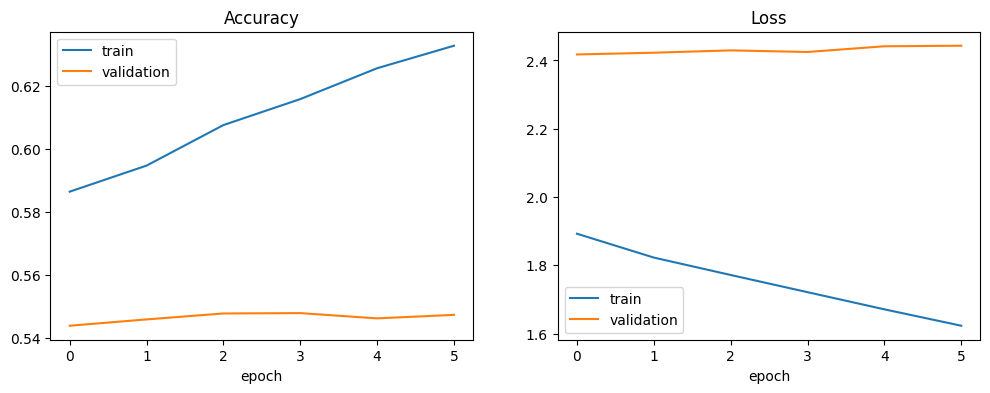

In [26]:
h4 = pd.DataFrame(history_e4.history)
print(f"best epoch: {h4['val_loss'].idxmin() + 1} of {len(h4)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["accuracy", "loss"]):
    ax.plot(h4[metric], label="train")
    ax.plot(h4["val_" + metric], label="validation")
    ax.set_title(metric.capitalize())
    ax.set_xlabel("epoch")
    ax.legend()
plt.show()

## 26. Compare all experiments on the validation set

In [27]:
e4_loss, e4_acc, e4_top5 = model_aug.evaluate(val_ds, verbose=0)

results = pd.DataFrame([
    ["E1", "frozen ResNet50 + new head",   val_loss, val_acc, val_top5],
    ["E2", "E1 + fine-tuning conv5",       ft_loss,  ft_acc,  ft_top5],
    ["E3", "E2 + data augmentation",       aug_loss, aug_acc, aug_top5],
    ["E4", "E3 + fine-tuning conv4",       e4_loss,  e4_acc,  e4_top5],
], columns=["experiment", "description", "val_loss", "val_accuracy", "val_top5_accuracy"])
results.round(4)

,experiment,description,val_loss,val_accuracy,val_top5_accuracy
0,E1,frozen ResNet50 + new head,2.8296,0.4858,0.6937
1,E2,E1 + fine-tuning conv5,2.5270,0.5242,0.7214
2,E3,E2 + data augmentation,2.4111,0.5431,0.7436
3,E4,E3 + fine-tuning conv4,2.4176,0.5440,0.7424


## Notes
No improvement: 54.4 % vs. 54.3 % (top-5 74.2 % vs. 74.4 %)
Best epoch: 1, afterwards only train accuracy rises (59 % → 63 %)
More trainable layers do not help at 128 × 128
Keep E3 (simpler, same performance); next: larger input size, label noise